# Стохастический градиентный и координатный спуски

## Загрузка и подготовка данных (1 балл)

**Загрузите уже знакомый вам файл *Advertising.csv* как объект DataFrame.** 

In [1379]:
#ваш код 
import pandas as pd
import numpy as np

data = pd.read_csv('data/Advertising.csv')
data.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


**Проверьте, есть ли в данных пропуски и, если они есть - удалите их**

In [1380]:
#ваш код 
data.info() # вывдим информацию о наборе данных
data.isnull().sum() # посчитаем количество пропусков

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


Unnamed: 0    0
TV            0
radio         0
newspaper     0
sales         0
dtype: int64

In [1381]:
#ваш код 

**Преобразуйте ваши признаки в массивы NumPy и разделите их на переменные X (предикторы) и y(целевая переменная)** 

In [1382]:
#ваш код 
X = np.array(data.drop(['sales', 'Unnamed: 0'], axis=1)) # создаём матрицу наблюдений исключив столбец с порядковым номером записи
y = np.array(data['sales']) # матрица целевого признака

## Координатный спуск (2 балла)

**Добавим единичный столбец для того, чтобы у нас был свободный коэффициент в уравнении регрессии:**

In [1383]:
#import numpy as np
X = np.insert(X, 0, np.ones(X.shape[0]), axis=1) # добавляем интерсепт
#X = np.hstack([np.ones(X.shape[0]).reshape(-1, 1), X])
y = y.reshape(-1, 1)
print(X.shape, y.shape)

(200, 4) (200, 1)


**Нормализуем данные: обычно это необходимо для корректной работы алгоритма**

In [1384]:
X = X / np.sqrt(np.sum(np.square(X), axis=0))

**Реализуйте алгоритм координатного спуска:**

Ниже приведен алгоритм координатного спуска для случая нормализованных данных:

**Задано:**

* $X=(x_{ij})$ - матрица наблюдений, размерностью $dim(X)=(m, n)$
* $N=1000$ - количество итераций

**Примечание:** *1000 итераций здесь указаны для этого задания, на самом деле их может быть намного больше, нет детерменированного значения.*

**Алгоритм (математическая запись):**
* Создать нулевой вектор параметров $w_0=(0, 0,..., 0)^T$
* Для всех $t=1, 2, ..., N$ итераций:
    * Для всех $k = 1, 2,..., n$:
        * Фиксируем значение всех признаков, кроме $k$-ого и вычисляем прогноз модели линейной регрессии.Для этого исключаем признак $k$-ый из данных и $w_j$ из параметров при построении прогноза.
        Математически это можно записать следующим образом:

        $$h_i = \sum_{j=1}^{k-1} x_{ij}w_{j} + \sum_{j=k+1}^{n} x_{ij}w_j $$

        **Примечание:**
        
        *Обратите, что в данной записи текущий признак под номером $k$ не участвует в сумме.Сравните эту запись с классической записью прогноза линейной регрессии в случае нормированных данных (когда участвуют все признаки):*

        $$h_i = \sum_{j=1}^{n} x_{ij}w_{j}$$ 
        
        * Вычисляем новое значение параметра $k$-ого коэффициента: 
        $$w_k = \sum_{i=1}^{m} x_{ik} (y_i - h_i) = x_k^T(y-h) $$

    * Вычисляем значение функции потерь и сохраняем в историю изменения функции потерь (В оценке функции потерь участвуют все признаки):
        $$\hat{y_i} = \sum_{j=1}^{n}x_{ij}w_j$$
        $$Loss_t = \frac{1}{n} \sum_{i=1}^{m}(y_i-\hat{y_i})^2$$
        
        или в векторном виде:
        
        $$\hat{y} = Xw$$
        $$Loss_t = \frac{1}{n}(y-\hat{y})^T(y-\hat{y})$$
    



**Алгоритм (псевдокод):**
```python

num_iters = #количество итераций
m = # количество строк в матрице X
n = # количество столбцов в матрице X
w = #вектор размера nx1, состояющий из нулей

for i in range(num_iters):
    for k in range(n):
        # Вычисляем прогноз без k-ого фактора
        h = (X[:,0:k] @ w[0:k]) + (X[:,k+1:] @ w[k+1:])
        # Обновляем новое значение k-ого коэффициента
        w[k] =  (X[:,k].T @ (y - h))
        # Вычисляем функцию потерь
        cost = sum((X @ w) - y) ** 2)/(len(y))

```

Вам необходимо реализовать координатный спуск, и вывести веса в модели линейной регрессии.

In [1385]:
# ваш код 
num_iters = 1000
m = X.shape[0]
n = X.shape[1]
w = np.zeros([n,1])

for i in range(num_iters):
    for k in range(n):
        h = (X[:, 0:k] @ w[0:k]) + (X[:, k+1:] @ w[k+1:])  # прогноз без k-ого фактора
        w[k] =  (X[:,k].T @ (y - h))  # пересчитываем k-ый коэффициент
        cost = sum(((X @ w) - y) ** 2)/(len(y))

print(w)

[[ 41.56217205]
 [110.13144155]
 [ 73.52860638]
 [ -0.55006384]]


Сравните результаты с реализацией линейной регрессии из библиотеки sklearn:

In [1386]:
from sklearn.linear_model import LinearRegression
 
model = LinearRegression(fit_intercept=False)
model.fit(X, y)
 
print("Веса модели полученные при помощи sklearn:             ", model.coef_)
print("Веса модели полученные при помощи координатного спуска:",w.T)

Веса модели полученные при помощи sklearn:              [[ 41.56217205 110.13144155  73.52860638  -0.55006384]]
Веса модели полученные при помощи координатного спуска: [[ 41.56217205 110.13144155  73.52860638  -0.55006384]]


Если вы все сделали верно, они должны практически совпасть!

## Стохастический градиентный спуск (7 баллов)

**Отмасштабируйте столбцы исходной матрицы *X* (которую мы не нормализовали еще!). Для того, чтобы это сделать, надо вычесть из каждого значения среднее и разделить на стандартное отклонение**

In [1387]:
#ваш код
X = np.array(data.drop(['sales', 'Unnamed: 0'], axis=1)) # создаём матрицу наблюдений
y = np.array(data['sales']) # матрица целевого признака

X = (X - X.mean(axis=0)) / X.std(axis=0)


**Добавим единичный столбец**

In [1388]:
X = np.hstack([np.ones(X.shape[0]).reshape(-1, 1), X])

**Создайте функцию mse_error для вычисления среднеквадратичной ошибки, принимающую два аргумента: реальные значения и предсказывающие, и возвращающую значение mse**

In [1389]:
#ваш код
def mse_error(y, y_pred):
    return np.mean((y - y_pred)**2)

**Сделайте наивный прогноз: предскажите продажи средним значением. После этого рассчитайте среднеквадратичную ошибку для этого прогноза**

In [1390]:
#ваш код
y_pred = np.full([y.shape[0], 1], y.mean())

print(mse_error(y, y_pred))

27.08574375


**Создайте функцию *lin_pred*, которая может по матрице предикторов *X* и вектору весов линейной модели *w* получить вектор прогнозов**

In [1391]:
#ваш код
def lin_pred(X, w):
    return np.dot(X, w).flatten()

**Создайте функцию *stoch_grad_step* для реализации шага стохастического градиентного спуска.  
Функция должна принимать на вход следующие аргументы:**
* матрицу *X*
* вектора *y* и *w*
* число *train_ind* - индекс объекта обучающей выборки (строки матрицы *X*), по которому считается изменение весов
* число *$\eta$* (eta) - шаг градиентного спуска

Результатом будет вектор обновленных весов

Шаг для стохастического градиентного спуска выглядит следующим образом:

$$\Large w_j \leftarrow w_j - \frac{2\eta}{\ell} \sum_{i=1}^\ell{{x_{ij}((w_0 + w_1x_{i1} + w_2x_{i2} +  w_3x_{i3}) - y_i)}}$$

Для того, чтобы написать функцию, нужно сделать следующее:
    
*  посчитать направление изменения: умножить объект обучающей выборки на 2 и на разницу между предсказанным значением и реальным, а потом поделить на количество элементов в выборке.
* вернуть разницу между вектором весов и направлением изменения, умноженным на шаг градиентного спуска

In [1392]:
#ваш код
def stoch_grad_step(X, y, w, train_ind, eta):
    grad = []  # создаём список для градиента
    for i in range(X.shape[1]):
        grad.append((np.dot(X[train_ind], w) - y[train_ind]) * 2 *X[train_ind,i])  # считаем составляющую для каждого признака 
    return w - eta / len(y) * np.array(grad)

**Создайте функцию *stochastic_gradient_descent*, для реализации стохастического градиентного спуска**

**Функция принимает на вход следующие аргументы:**
- Матрицу признаков X
- Целевую переменнную
- Изначальную точку (веса модели)
- Параметр, определяющий темп обучения
- Максимальное число итераций
- Евклидово расстояние между векторами весов на соседних итерациях градиентного спуска,при котором алгоритм прекращает работу 

**На каждой итерации в вектор (список) должно записываться текущее значение среднеквадратичной ошибки. Функция должна возвращать вектор весов $w$, а также вектор (список) ошибок.**

Алгоритм сследующий:
    
* Инициализируйте расстояние между векторами весов на соседних итерациях большим числом (можно бесконечностью)
* Создайте пустой список для фиксации ошибок
* Создайте счетчик итераций
* Реализуйте оновной цикл обучения пока расстояние между векторами весов больше того, при котором надо прекратить работу (когда расстояния станут слишком маленькими - значит, мы застряли в одном месте) и количество итераций меньше максимально разрешенного: сгенерируйте случайный индекс, запишите текущую ошибку в вектор ошибок, запишите в переменную текущий шаг стохастического спуска с использованием функции, написанной ранее. Далее рассчитайте текущее расстояние между векторами весов и прибавьте к счетчику итераций 1.
* Верните вектор весов и вектор ошибок

In [1393]:
# ваш код
def stochastic_gradient_descent(X, y, w, eta, max_iter, min_dist):
    dist = np.inf  # начальное расстояние мнжду векторами
    mse = []  #  список ошибок
    i = 0  #  счётчик
    np.random.seed(42)  # фиксируем seed
    while dist > min_dist and i < max_iter:
        index = np.random.randint(X.shape[0])  # генерируем случайный индекс
        mse.append(mse_error(lin_pred(X, w), y))  # записываем ошибку в список
        w_cur = stoch_grad_step(X, y, w, index, eta)  # пересчитываем веса
        dist = np.linalg.norm(w_cur - w)  # вычисляем расстояние между векторами весов до и после итерации
        i += 1  
        w = w_cur  
    return w, mse

w = np.zeros([4, 1])
max_iter = 10**5
eta = 0.01
min_dist = 1e-8

w_sgd, mse_sgd = stochastic_gradient_descent(X, y, w, eta, max_iter, min_dist)


 **Запустите $10^5$ итераций стохастического градиентного спуска. Укажите вектор начальных весов, состоящий из нулей. Можете поэкспериментировать с параметром, отвечающим за темп обучения.**

**Постройте график зависимости ошибки от номера итерации**

Text(0, 0.5, 'MSE')

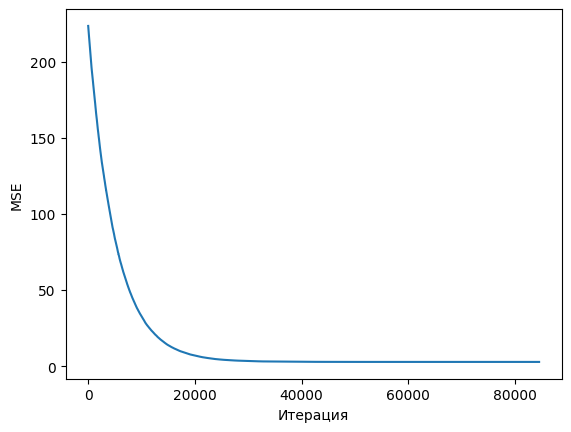

In [1394]:
# ваш код
import matplotlib.pyplot as plt

plt.plot(range(len(mse_sgd)), mse_sgd)
plt.xlabel('Итерация')
plt.ylabel('MSE')

**Выведите вектор весов, к которому сошелся метод.**

In [1395]:
# ваш код
print(w_sgd)

[[ 1.40190566e+01]
 [ 3.91069256e+00]
 [ 2.78209808e+00]
 [-8.10462217e-03]]


**Выведите среднеквадратичную ошибку на последней итерации.**

In [1396]:
# ваш код
print(mse_sgd[-1])

2.784412588352759
